# Лабораторная работа 1.2.5

In [78]:
import numpy as np
import pandas as pd
import sympy as sp
import matplotlib.pyplot as plt
from scipy import stats
from pathlib import Path
from IPython.display import display
export_dir = Path('generated')

In [79]:
%history


import numpy as np
import pandas as pd
import sympy as sp
import matplotlib.pyplot as plt
from scipy import stats
from pathlib import Path
from IPython.display import display
%history
def save_formulas(filename, equations):
    text = ''
    for equation in equations:
        display(equation)
        text += r'\[\displaystyle ' + sp.latex(equation) + r'\]' + '\n'
    (export_dir / filename).write_text(text, encoding='utf-8')


def error_formulas(name, expression, variables):
    # Возвращаем расчётную формулу, её производные и итоговую ошибку.
    result = sp.Symbol(name)
    function = sp.Function(name)(*variables)
    equations = [sp.Eq(result, expression)]
    variance = 0
    for variable in variables:
        derivative = sp.diff(expression, variable)
        equations.append(sp.Eq(sp.Derivative(function, variable), derivative))
        uncertainty = sp.Symbol(r'\sigma_{' + sp.latex(variable) + '}', positive=True)
        variance += (derivative * uncertainty)**2
    error = sp.s

### Функции для сохранения в LaTeX

In [80]:
def save_formulas(filename, equations):
    text = ''
    for equation in equations:
        display(equation)
        text += r'\[\displaystyle ' + sp.latex(equation) + r'\]' + '\n'
    (export_dir / filename).write_text(text, encoding='utf-8')


def error_formulas(name, expression, variables):
    # Возвращаем расчётную формулу, её производные и итоговую ошибку.
    result = sp.Symbol(name)
    function = sp.Function(name)(*variables)
    equations = [sp.Eq(result, expression)]
    variance = 0
    for variable in variables:
        derivative = sp.diff(expression, variable)
        equations.append(sp.Eq(sp.Derivative(function, variable), derivative))
        uncertainty = sp.Symbol(r'\sigma_{' + sp.latex(variable) + '}', positive=True)
        variance += (derivative * uncertainty)**2
    error = sp.sqrt(variance)
    equations.append(sp.Eq(sp.Symbol(r'\sigma_{' + sp.latex(result) + '}'), error))
    return equations

In [81]:
def save_table(filename, table):
    text = table.to_latex(index=False, escape=False, float_format=str)
    (export_dir / filename).write_text(text, encoding='utf-8')


def save_results(filename, lines):
    text = ''
    for line in lines:
        text += r'\noindent $' + line + r'$\par\vspace{3mm}' + '\n'
    (export_dir / filename).write_text(text, encoding='utf-8')

## 1. Прецессия

In [82]:
g = 9.81 
l = 120  # мм

In [83]:
# анные для разных масс навешанных на гироскоп
data = {
    'mass': [218.7, 218.7, 218.7, 218.7, 141.7, 141.7, 141.7, 340.3, 340.3, 340.3, 91.5, 91.5, 116.1, 116.1],  # г
    'revolutions_N': [3, 2, 4, 4, 3, 3, 3, 3, 3, 3, 3, 3, 2.5, 3],
    'time_t': [2*60+14, 60+30, 180+1, 120+59, 180+29, 180+29, 180+29, 60+27, 60+28, 60+27, 5*60+25, 5*60+24, 180+34, 60*4+15], 

}

In [84]:
df = pd.DataFrame(data)

l_m = l / 1000

df['M'] = df['mass'] / 1000 * g * l_m
df['Omega'] = 2 * np.pi * df['revolutions_N'] / df['time_t']
df

,mass,revolutions_N,time_t,M,Omega
0,218.7,3.0,134,0.257454,0.140668
1,218.7,2.0,90,0.257454,0.139626
2,218.7,4.0,181,0.257454,0.138855
3,218.7,4.0,179,0.257454,0.140406
4,141.7,3.0,209,0.166809,0.090189
5,141.7,3.0,209,0.166809,0.090189
6,141.7,3.0,209,0.166809,0.090189
7,340.3,3.0,87,0.400601,0.216662
8,340.3,3.0,88,0.400601,0.214199
9,340.3,3.0,87,0.400601,0.216662


### Формулы и погрешности

In [108]:
m_s, l_s, g_s, N_s, t_s = sp.symbols('m l g N t', positive=True)
M_s, Omega_s, L_s = sp.symbols('M Omega L', positive=True)

Omega_expr = 2 * sp.pi * N_s / t_s

save_formulas('precession_formulas.tex', [
] + error_formulas('Omega', Omega_expr, [N_s, t_s]))

Eq(Omega, 2*pi*N/t)

Eq(Derivative(Omega(N, t), N), 2*pi/t)

Eq(Derivative(Omega(N, t), t), -2*pi*N/t**2)

Eq(\sigma_{\Omega}, sqrt(4*pi**2*N**2*\sigma_{t}**2/t**4 + 4*pi**2*\sigma_{N}**2/t**2))

### Средние по массам

In [86]:
summary = df.groupby('mass').agg(
    repeats=('Omega', 'size'),
    M=('M', 'first'),
    Omega=('Omega', 'mean'),
    sigma_Omega=('Omega', 'sem'),
).reset_index()

summary

,mass,repeats,M,Omega,sigma_Omega
0,91.5,2,0.107714,0.058088,0.000090
1,116.1,2,0.136673,0.073661,0.000259
2,141.7,3,0.166809,0.090189,0.000000
3,218.7,4,0.257454,0.139889,0.000410
4,340.3,3,0.400601,0.215841,0.000821


In [87]:
raw_table = df[['mass', 'revolutions_N', 'time_t', 'M', 'Omega']].round(5)
raw_table.columns = ['m, г', 'N', 't, с', 'M, Н м', r'$\Omega$, рад/с']
save_table('raw_table.tex', raw_table)

averaged_table = summary.round(5)
averaged_table.columns = ['m, г', 'k', 'M, Н м', r'$\overline{\Omega}$, рад/с', r'$\sigma_\Omega$, рад/с']
save_table('averaged_table.tex', averaged_table)

### МНК: 

In [88]:
x = summary['M'].to_numpy()
y = summary['Omega'].to_numpy()

a = np.sum(x*y) / np.sum(x**2)
residuals = y - a*x
sigma_a = np.sqrt(np.sum(residuals**2) / (len(x)-1) / np.sum(x**2))

L = 1 / a
sigma_L = sigma_a / a**2

In [89]:
print('a =', round(a, 5), '±', round(sigma_a, 5))
print('L =', round(L, 4), '±', round(sigma_L, 4), 'кг·м²/с')

free_fit = stats.linregress(x, y)
print('b =', round(free_fit.intercept, 5), '±', round(free_fit.intercept_stderr, 5))

a = 0.54007 ± 0.00095
L = 1.8516 ± 0.0032 кг·м²/с
b = 0.0002 ± 0.00057


In [120]:
a_s, I_s = sp.symbols('a I_0', positive=True)
nu_s, omega_s = sp.symbols('nu omega_0', positive=True)

save_formulas('fit_formulas.tex', [
    sp.Eq(Omega_s, a_s*M_s),
    #sp.Eq(sp.Symbol('sigma_L'), sp.Symbol('sigma_a')/a_s**2),
])

save_results('precession_results.tex', [
    rf'a=({round(a,5)}\pm{round(sigma_a,5)})\; (\text{{Н м с}})^{{-1}}',
    #rf'L=({round(L,4)}\pm{round(sigma_L,4)})\;\text{{кг м}}^2/\text{{с}}',
])

Eq(Omega, M*a)

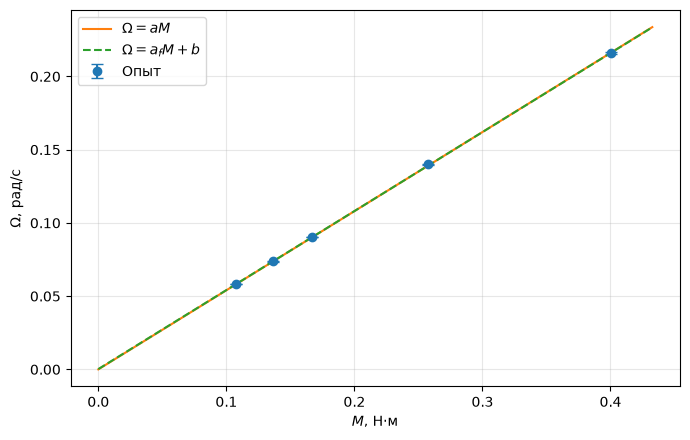

In [91]:
x_line = np.linspace(0, x.max()*1.08, 100)

plt.figure(figsize=(7, 4.5))
plt.errorbar(x, y, yerr=summary['sigma_Omega'], fmt='o', capsize=4, label='Опыт')
plt.plot(x_line, a*x_line, label=r'$\Omega=aM$')
plt.plot(x_line, free_fit.slope*x_line + free_fit.intercept, '--', label=r'$\Omega=a_fM+b$')

plt.xlabel(r'$M$, Н·м')
plt.ylabel(r'$\Omega$, рад/с')
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(export_dir / 'precession.pdf')
plt.savefig(export_dir / 'precession.png', dpi=170)
plt.show()

## 2. Момент инерции ротора

In [92]:
m_cylinder = 1.6158  # кг
D_cylinder = 7.8     # см
R_cylinder = D_cylinder / 100 / 2

rotor = pd.DataFrame({'n': [10, 10], 't': [31.76, 31.39]})
cylinder = pd.DataFrame({'n': [10, 10], 't': [40.20, 40.37]})

In [93]:
rotor['T'] = rotor['t'] / rotor['n']
cylinder['T'] = cylinder['t'] / cylinder['n']

display(rotor)
display(cylinder)

,n,t,T
0,10,31.76,3.176
1,10,31.39,3.139


,n,t,T
0,10,40.20,4.020
1,10,40.37,4.037


In [94]:
T_0 = rotor['T'].mean()
T_c = cylinder['T'].mean()

sigma_T_0 = rotor['T'].sem()
sigma_T_c = cylinder['T'].sem()

print('T_0 =', T_0, '±', round(sigma_T_0, 4), 'с')
print('T_c =', T_c, '±', round(sigma_T_c, 4), 'с')

T_0 = 3.1575 ± 0.0185 с
T_c = 4.0285 ± 0.0085 с


### Формула, производные и погрешность

In [95]:
mc_s, Rc_s, T0_s, Tc_s = sp.symbols('m_c R_c T_0 T_c', positive=True)

I_expr = mc_s * Rc_s**2 / 2 * (T0_s / Tc_s)**2

save_formulas('inertia_formulas.tex',
              error_formulas('I_0', I_expr, [mc_s, Rc_s, T0_s, Tc_s]))

Eq(I_0, R_c**2*T_0**2*m_c/(2*T_c**2))

Eq(Derivative(I_0(m_c, R_c, T_0, T_c), m_c), R_c**2*T_0**2/(2*T_c**2))

Eq(Derivative(I_0(m_c, R_c, T_0, T_c), R_c), R_c*T_0**2*m_c/T_c**2)

Eq(Derivative(I_0(m_c, R_c, T_0, T_c), T_0), R_c**2*T_0*m_c/T_c**2)

Eq(Derivative(I_0(m_c, R_c, T_0, T_c), T_c), -R_c**2*T_0**2*m_c/T_c**3)

Eq(\sigma_{I_{0}}, sqrt(R_c**4*T_0**4*\sigma_{m_{c}}**2/(4*T_c**4) + R_c**4*T_0**4*\sigma_{T_{c}}**2*m_c**2/T_c**6 + R_c**4*T_0**2*\sigma_{T_{0}}**2*m_c**2/T_c**4 + R_c**2*T_0**4*\sigma_{R_{c}}**2*m_c**2/T_c**4))

In [96]:
values = {mc_s: m_cylinder, Rc_s: R_cylinder, T0_s: T_0, Tc_s: T_c}
I_0 = float(I_expr.subs(values))

# Численно учитываем только разброс периодов.
sigma_I_0 = I_0 * np.sqrt((2*sigma_T_0/T_0)**2 + (2*sigma_T_c/T_c)**2)

print('I_0 =', I_0, 'кг·м²')
print('sigma_I_0 =', sigma_I_0, 'кг·м²')

I_0 = 0.0007548954446693643 кг·м²
sigma_I_0 = 9.402083772416598e-06 кг·м²


In [97]:
rotor_table = rotor.rename(columns={'n': 'n', 't': 't, с', 'T': 'T, с'})
cylinder_table = cylinder.rename(columns={'n': 'n', 't': 't, с', 'T': 'T, с'})

save_table('rotor_torsion.tex', rotor_table)
save_table('cylinder_torsion.tex', cylinder_table)

save_results('inertia_results.tex', [
    rf'T_0=({round(T_0,4)}\pm{round(sigma_T_0,4)})\;\text{{с}}',
    rf'T_c=({round(T_c,4)}\pm{round(sigma_T_c,4)})\;\text{{с}}',
    rf'I_0=({round(I_0*10**4,3)}\pm{round(sigma_I_0*10**4,3)})\cdot10^{{-4}}\;\text{{кг м}}^2',
])

## 3. Частота вращения

In [98]:
nu_lissajous = 400  # Гц
omega_lissajous = 2 * np.pi * nu_lissajous

nu = 1 / (2*np.pi*a*I_0)
sigma_nu = nu * np.sqrt((sigma_a/a)**2 + (sigma_I_0/I_0)**2)

difference = (nu / nu_lissajous - 1) * 100
slow_ratio = df['Omega'].max() / omega_lissajous

In [99]:
print('Частота по прецессии:', round(nu, 1), '±', round(sigma_nu, 1), 'Гц')
print('Частота по Лиссажу:', nu_lissajous, 'Гц')
print('Расхождение:', round(difference, 2), '%')
print('max(Omega) / omega_0 =', slow_ratio)

Частота по прецессии: 390.4 ± 4.9 Гц
Частота по Лиссажу: 400 Гц
Расхождение: -2.41 %
max(Omega) / omega_0 = 8.620689655172413e-05


In [100]:
nu_expr = 1 / (2*sp.pi*a_s*I_s)

save_formulas('frequency_formulas.tex', [sp.Eq(omega_s, 2*sp.pi*nu_s)] +
              error_formulas('nu', nu_expr, [a_s, I_s]))

Eq(omega_0, 2*pi*nu)

Eq(nu, 1/(2*pi*I_0*a))

Eq(Derivative(nu(a, I_0), a), -1/(2*pi*I_0*a**2))

Eq(Derivative(nu(a, I_0), I_0), -1/(2*pi*I_0**2*a))

Eq(\sigma_{\nu}, sqrt(\sigma_{a}**2/(4*pi**2*I_0**2*a**4) + \sigma_{I_{0}}**2/(4*pi**2*I_0**4*a**2)))

In [101]:
save_results('frequency_results.tex', [
    rf'\nu=({round(nu,1)}\pm{round(sigma_nu,1)})\;\text{{Гц}}',
    rf'\nu_{{\text{{Лиссажу}}}}={nu_lissajous}\;\text{{Гц}}',
    rf'\delta={round(difference,2)}\%',
    rf'\Omega_{{\max}}/\omega_0={round(slow_ratio*10**5,2)}\cdot10^{{-5}}',
])

## 4. Момент трения

In [ ]:
r_hyro = 12.5 # см, радиус гироскопа до точки прикладывания груза
# 1) 
drop = {
    'mass':[320.3, 320.3, 116.1, 116.1],
    'revolutions':[3,3,2.5,3],
    'drop': [15-12.5, 15-13, 16-11, 16-11.5]
}

$\Delta\theta\approx h/r$, $M_f\approx L\Delta\theta/t$. Подставим $L=M/\Omega$, $\Omega t=2\pi N$.

In [103]:
drop_df = pd.DataFrame(drop)

drop_df['M'] = drop_df['mass'] / 1000 * g * l_m
drop_df['theta'] = drop_df['drop'] / r_hyro
drop_df['friction'] = drop_df['M'] * drop_df['theta'] / (2*np.pi*drop_df['revolutions'])

drop_df

,mass,revolutions,drop,M,theta,friction
0,320.3,3.0,2.5,0.377057,0.20,0.004001
1,320.3,3.0,2.0,0.377057,0.16,0.003201
2,116.1,2.5,6.0,0.136673,0.48,0.004176
3,116.1,3.0,4.5,0.136673,0.36,0.002610


In [113]:
h_s, r_s = sp.symbols('h r', positive=True)
friction_expr = M_s*h_s / (2*sp.pi*r_s*N_s)

save_formulas('friction_formulas.tex', [
    sp.Eq(sp.Symbol('M_f'), friction_expr),

    sp.Eq(
        sp.Derivative(sp.Function('M_f')(h_s), h_s),
        sp.diff(friction_expr, h_s)
    ),

    sp.Eq(
        sp.Symbol(r'\sigma_{M_f}'),
        sp.diff(friction_expr, h_s) * sp.Symbol(r'\sigma_h')
    )
])

Eq(M_f, M*h/(2*pi*N*r))

Eq(Derivative(M_f(h), h), M/(2*pi*N*r))

Eq(\sigma_{M_f}, M*\sigma_h/(2*pi*N*r))

Времена первых двух опытов не записаны. Для двух последних сопоставление времён условное.

In [105]:
drop_df['t'] = [np.nan, np.nan, data['time_t'][-2], data['time_t'][-1]]
drop_df['v'] = drop_df['drop'] / 100 / drop_df['t']
drop_df['angular_speed'] = drop_df['theta'] / drop_df['t']

drop_df[['mass', 't', 'v', 'angular_speed']]

,mass,t,v,angular_speed
0,320.3,NaN,NaN,NaN
1,320.3,NaN,NaN,NaN
2,116.1,214.0,0.000280,0.002243
3,116.1,255.0,0.000176,0.001412


In [106]:
friction_table = drop_df[['mass', 'revolutions', 'drop', 'theta', 'friction']].copy()
friction_table['friction'] *= 1000  # мН·м
friction_table = friction_table.round(3)
friction_table.columns = ['m, г', 'N', 'h, см', r'$\Delta\theta$, рад', r'$M_f$, мН м']

save_table('friction_table.tex', friction_table)

In [ ]:
# расчет погрешности с учетом погрешности систематической линейки
ruler_step = 0.1  # см, цена деления 1 мм
sigma_height = ruler_step / 2
sigma_h = np.sqrt(2) * sigma_height  # см

drop_df = pd.DataFrame(drop)

drop_df['M'] = drop_df['mass'] / 1000 * g * l_m
drop_df['theta'] = drop_df['drop'] / r_hyro

drop_df['friction'] = (
    drop_df['M'] * drop_df['theta']
    / (2 * np.pi * drop_df['revolutions'])
)


drop_df['sigma_friction'] = (
    drop_df['friction'] * sigma_h / drop_df['drop']
)


drop_df['t'] = [
    np.nan, np.nan,
    data['time_t'][-2], data['time_t'][-1]
]

drop_df['v'] = drop_df['drop'] / 100 / drop_df['t']
drop_df['sigma_v'] = sigma_h / 100 / drop_df['t']

drop_df['angular_speed'] = drop_df['theta'] / drop_df['t']
drop_df['sigma_angular_speed'] = sigma_h / r_hyro / drop_df['t']

display(drop_df)


,mass,revolutions,drop,M,theta,friction,sigma_friction,t,v,sigma_v,angular_speed,sigma_angular_speed
0,320.3,3.0,2.5,0.377057,0.20,0.004001,0.000113,NaN,NaN,NaN,NaN,NaN
1,320.3,3.0,2.0,0.377057,0.16,0.003201,0.000113,NaN,NaN,NaN,NaN,NaN
2,116.1,2.5,6.0,0.136673,0.48,0.004176,0.000049,214.0,0.000280,0.000003,0.002243,0.000026
3,116.1,3.0,4.5,0.136673,0.36,0.002610,0.000041,255.0,0.000176,0.000003,0.001412,0.000022


In [118]:
sh, sh1, sh2 = sp.symbols(r'\sigma_h \sigma_1 \sigma_2', positive=True)
h, t, Mf = sp.symbols('h t M_f', positive=True)

equations = [
    sp.Eq(sh, sp.sqrt(sh1**2 + sh2**2)),
    sp.Eq(sp.Symbol(r'\sigma_v'), sh / t),
    sp.Eq(sp.Symbol(r'\sigma_{M_f}'), Mf * sh / h),
    sp.Eq(sp.Symbol(r'\sigma_{\dot{\theta}}'), sh / (r_s * t))
]

save_formulas('drop_errors.tex', equations)

friction_table = pd.DataFrame({
    'm, г': drop_df['mass'],
    'N': drop_df['revolutions'],
    'h, см': drop_df['drop'],
    r'$\sigma_h$, см': sigma_h,
    r'$M_f$, мН м': drop_df['friction'] * 1000,
    r'$\sigma_{M_f}$, мН м': drop_df['sigma_friction'] * 1000
})

save_table('friction_table.tex', friction_table.round(3))

'''
speed_table = pd.DataFrame({
    'm, г': drop_df['mass'],
    'N': drop_df['revolutions'],
    'v, мм/с': drop_df['v'] * 1000,
    r'$\sigma_v$, мм/с': drop_df['sigma_v'] * 1000,
    r'$\dot{\theta}$, мрад/с': drop_df['angular_speed'] * 1000,
    r'$\sigma_{\dot{\theta}}$, мрад/с': drop_df['sigma_angular_speed'] * 1000
})
'''
speed_table = speed_table.round(3).fillna('---')
save_table('drop_speed_table.tex', speed_table)
friction_file = export_dir / 'friction_table.tex'

text = (export_dir / 'drop_errors.tex').read_text(encoding='utf-8')
text += r'{\raggedright здесь мы учитваем только систематическую погрешность цены деления линейки— 1 мм.\par}' + '\n'
text += r'{\raggedright Погрешность измерения рычага ротора не была указана \par}' + '\n'
text += r'\par\vspace{3mm}' + '\n'
text += friction_file.read_text(encoding='utf-8')
text += r'\par\vspace{5mm}' + '\n'
#text += (export_dir / 'drop_speed_table.tex').read_text(encoding='utf-8')

friction_file.write_text(text, encoding='utf-8')

<>:29: SyntaxWarning: invalid escape sequence '\s'
<>:29: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_168974/514349818.py:29: SyntaxWarning: invalid escape sequence '\s'
  r'$\sigma_v$, мм/с': drop_df['sigma_v'] * 1000,


Eq(\sigma_h, sqrt(\sigma_1**2 + \sigma_2**2))

Eq(\sigma_v, \sigma_h/t)

Eq(\sigma_{M_f}, M_f*\sigma_h/h)

Eq(\sigma_{\dot{\theta}}, \sigma_h/(r*t))

774